In [1]:
from pathlib import Path
import json
import torch
torch.set_num_threads(4)
import pandas as pd
from IPython.display import display, Image, Markdown
RETRAIN = False
EPOCHS = 5
if RETRAIN or not Path('training_output/run_config.json').exists():
    display(run(epochs=EPOCHS))
else:
    print('Đọc kết quả thực nghiệm đã lưu; đặt RETRAIN=True để chạy lại.')
display(pd.Series(json.loads(Path('training_output/run_config.json').read_text())))

F:\HUS\.venv-ner\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Đọc kết quả thực nghiệm đã lưu; đặt RETRAIN=True để chạy lại.


model                          google/bert_uncased_L-2_H-128_A-2
seed                                                          42
epochs                                                         5
best_epoch                                                     4
lr                                                        0.0005
batch_size                                                    32
chunk_words                                                   64
alignment                first subword; others and specials -100
device                                                       cpu
split_sizes    {'train': 14041, 'validation': 3250, 'test': 3...
selection                            validation strict entity F1
dataset                   eriktks/conll2003 refs/convert/parquet
torch                                                 2.15.0+cpu
recovery       Checkpoint and 5-epoch history survived drive ...
dtype: object

In [ ]:
"""Train a compact pretrained Transformer and export LAB 09 experiments."""
import json
import random
import time
import copy
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForTokenClassification, DataCollatorForTokenClassification
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from baseline_ner import ROOT, MODEL, LABELS, SEED, align, load_data, evaluate, spans, save_predictions
from information_extraction import CHUNK_WORDS, chunks, predict



In [ ]:
def train_transformer(data,epochs=5,lr=5e-4):
    random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
    torch.set_num_threads(min(8,torch.get_num_threads()))
    device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    tokenizer=AutoTokenizer.from_pretrained(MODEL,use_fast=True,model_max_length=512)
    model=AutoModelForTokenClassification.from_pretrained(MODEL,num_labels=len(LABELS),
              id2label=dict(enumerate(LABELS)),label2id={l:i for i,l in enumerate(LABELS)},use_safetensors=True).to(device)
    items,_=chunks(data['train'],tokenizer)
    loader=DataLoader(items,batch_size=32,shuffle=True,generator=torch.Generator().manual_seed(SEED),
                      collate_fn=DataCollatorForTokenClassification(tokenizer))
    optimizer=torch.optim.AdamW(model.parameters(),lr=lr,weight_decay=.01)
    best=-1.; history=[]; start=time.perf_counter()
    for epoch in range(epochs):
        model.train(); losses=[]
        for batch in loader:
            optimizer.zero_grad(); loss=model(**{k:v.to(device) for k,v in batch.items()}).loss
            loss.backward(); torch.nn.utils.clip_grad_norm_(model.parameters(),1.); optimizer.step(); losses.append(loss.item())
        valpred=predict(model,tokenizer,data['validation'],device)
        metrics,_,_=evaluate(data['validation'],valpred)
        entry=dict(epoch=epoch+1,loss=float(np.mean(losses)),validation_f1=metrics['f1'])
        history.append(entry); print(entry,flush=True)
        if metrics['f1']>best:
            best=metrics['f1']; best_state=copy.deepcopy(model.state_dict()); best_epoch=epoch+1
    seconds=time.perf_counter()-start
    model.load_state_dict(best_state)
    output=ROOT/'training_output/ner_model'; model.save_pretrained(output); tokenizer.save_pretrained(output)
    pd.DataFrame(history).to_csv(ROOT/'training_output/training_history.csv',index=False)
    predictions=predict(model,tokenizer,data['test'],device); save_predictions('transformer',data['test'],predictions)
    metrics,types,lengths=evaluate(data['test'],predictions)
    config=dict(model=MODEL,seed=SEED,epochs=epochs,best_epoch=best_epoch,lr=lr,batch_size=32,chunk_words=CHUNK_WORDS,
                model_revision=getattr(model.config,'_commit_hash',None),
                alignment='first subword; others and specials -100',device=str(device),
                split_sizes={k:len(v) for k,v in data.items()},selection='validation strict entity F1',
                dataset='eriktks/conll2003 refs/convert/parquet',torch=torch.__version__)
    (ROOT/'training_output/run_config.json').write_text(json.dumps(config,indent=2),encoding='utf-8')
    return dict(model='transformer',train_seconds=seconds,**metrics),types,lengths,predictions


In [ ]:
def analysis(data,outputs):
    rows=data['test']; all_types=[]; all_lengths=[]
    for name,(_,types,lengths,_) in outputs.items():
        all_types.extend(dict(model=name,**r) for r in types)
        all_lengths.extend(dict(model=name,**r) for r in lengths)
    pd.DataFrame([v[0] for v in outputs.values()]).to_csv(ROOT/'results.csv',index=False)
    pd.DataFrame(all_types).to_csv(ROOT/'entity_metrics.csv',index=False)
    lengths=pd.DataFrame(all_lengths); lengths.to_csv(ROOT/'training_output/entity_length_metrics.csv',index=False)
    fig,ax=plt.subplots(figsize=(8,5))
    for name in outputs:
        frame=lengths[lengths.model==name]; ax.plot(frame.length,frame.f1,marker='o',label=name)
    ax.set(xlabel='Entity length (words)',ylabel='Strict entity F1',ylim=(0,1),title='CoNLL-2003 test: exact span and type')
    ax.legend(); ax.grid(alpha=.25); fig.tight_layout(); fig.savefig(ROOT/'entity_length_analysis.png',dpi=160); plt.close(fig)
    fig,axes=plt.subplots(1,2,figsize=(15,6))
    gold=[t for r in rows for t in r['tags']]
    for ax,(name,output) in zip(axes,outputs.items()):
        pred=[t for ts in output[3] for t in ts]
        ConfusionMatrixDisplay(confusion_matrix(gold,pred,labels=LABELS),display_labels=LABELS).plot(ax=ax,colorbar=False,xticks_rotation=45,cmap='Blues',values_format='d')
        ax.set_title(name+' - word-level BIO counts')
    fig.tight_layout(); fig.savefig(ROOT/'confusion_matrix.png',dpi=160); plt.close(fig)
    write_errors(data,outputs)


In [ ]:
def write_errors(data,outputs):
    rows=data['test']; predictions=outputs['transformer'][3]
    train_freq=Counter((' '.join(r['tokens'][a:b]).lower(),t) for r in data['train'] for a,b,t in spans(r['tags']))
    lines=['# LAB 09 - Phân tích lỗi','', 'Các ví dụ dưới đây được chọn tự động từ dự đoán thật trên test, đánh giá strict IOB2. FP/FN có thể trùng ví dụ boundary vì exact-match coi sai boundary là cả FP và FN. Chỉ số tần suất tính trên train; chưa đủ để kết luận quan hệ nhân quả.','']
    groups=defaultdict(list); rarity=Counter()
    for row,pred in zip(rows,predictions):
        gs,ps=spans(row['tags']),spans(pred)
        for a,b,t in gs:
            rarity['rare_total' if train_freq[(' '.join(row['tokens'][a:b]).lower(),t)]<=1 else 'seen_total']+=1
            if (a,b,t) not in ps:
                rarity['rare_missed' if train_freq[(' '.join(row['tokens'][a:b]).lower(),t)]<=1 else 'seen_missed']+=1
        for s in sorted(ps-gs): groups['False positives'].append((row,pred,s,'spurious entity / wrong type hoặc boundary'))
        for s in sorted(gs-ps): groups['False negatives'].append((row,pred,s,'missing entity / wrong type hoặc boundary'))
        for s in sorted(gs-ps):
            if any(s[2]==q[2] and max(s[0],q[0])<min(s[1],q[1]) and s[:2]!=q[:2] for q in ps):
                groups['Boundary errors'].append((row,pred,s,'Có span dự đoán cùng loại chồng lấn, nhưng sai điểm đầu/cuối.'))
    escape=lambda s:s.replace('|','/').replace('\n',' ')
    for title in ['False positives','False negatives','Boundary errors']:
        examples=groups[title][:5]
        lines.extend([f'## {title} ({len(examples)} ví dụ; tổng {len(groups[title])})','','| Text | Gold | Prediction | Error type | Explanation |','|---|---|---|---|---|'])
        for row,pred,(a,b,t),explain in examples:
            text=' '.join(row['tokens']); surface=' '.join(row['tokens'][a:b]); freq=train_freq[(surface.lower(),t)]
            gold='; '.join(f'{a}:{b} {t}='+ ' '.join(row['tokens'][a:b]) for a,b,t in sorted(spans(row['tags'])))
            p='; '.join(f'{a}:{b} {t}='+ ' '.join(row['tokens'][a:b]) for a,b,t in sorted(spans(pred)))
            counterpart=spans(row['tags']) if title=='False positives' else spans(pred)
            overlap=sorted(q for q in counterpart if max(a,q[0])<min(b,q[1]))
            exact_boundary=[q for q in overlap if q[:2]==(a,b)]
            if exact_boundary:
                category='wrong entity type'
                detail=f'Cùng span {a}:{b}, nhãn đang xét {t}, nhãn phía đối chiếu {exact_boundary[0][2]}. Không phải lỗi boundary.'
            elif overlap:
                category='wrong boundary' if any(q[2]==t for q in overlap) else 'wrong type + boundary'
                detail=f'Span đang xét {a}:{b} ({t}); phía đối chiếu chồng lấn: {overlap}. Tách tên hoặc thiếu từ làm exact-match thất bại.'
            else:
                category='spurious entity' if title=='False positives' else 'missing entity'
                detail='Không có entity nào phía đối chiếu chồng lấn span này. Cần phân biệt từ thường với tên riêng dựa vào ngữ cảnh.'
            lines.append('| '+' | '.join(map(escape,[text,gold or 'O',p or 'O',category,f'{detail} Cụm kiểm tra: {surface}; số lần surface/type trong train={freq}.']))+' |')
        lines.append('')
    surfaces=defaultdict(dict)
    for row,pred in zip(rows,predictions):
        for a,b,t in sorted(spans(row['tags'])):
            surface=' '.join(row['tokens'][a:b]); surfaces[surface].setdefault(t,(row,pred))
    ambiguous=[(s,v) for s,v in sorted(surfaces.items()) if len(v)>1][:3]
    lines.extend(['## Cùng surface form, khác entity type',''])
    for surface,variants in ambiguous:
        lines.append(f'### {surface}')
        for t,(row,pred) in variants.items():
            lines.append(f'- Gold {t}: '+ ' '.join(row['tokens']) + '; dự đoán: '+str([(a,b,k) for a,b,k in sorted(spans(pred))]))
    lines.extend(['','Contextual representation cho mỗi từ phụ thuộc các từ xung quanh nên có thể phân biệt tên quốc gia với đội tuyển/tổ chức trong tin thể thao. Baseline cũng có hai từ lân cận nhưng không học được quan hệ xa như self-attention. Không thể chỉ dựa vào hình thức viết hoa.','', '## Entity hiếm', '',str(dict(rarity)), '', 'Rare = surface viết thường + loại xuất hiện tối đa 1 lần trong train. Missed = không khớp chính xác span và loại. So sánh tỷ lệ missed/total, không so số đếm thuần túy.','', '## Tokenization, context và domain', '', 'Strategy A dùng word_ids để giữ nhãn ở subword đầu, bỏ các vị trí khác khỏi loss và metric. Các chunk 64 từ được ghép lại trước khi chấm điểm nên không bỏ từ test. Chunk có thể làm mất ngữ cảnh qua biên; đó là một hạn chế thực nghiệm. Uncased BERT mất tín hiệu viết hoa, trong khi baseline sử dụng trực tiếp tín hiệu này. PER/LOC/ORG/MISC có độ phổ biến, tính mơ hồ và boundary khác nhau; xem support trong entity_metrics.csv. CoNLL là tin tức tiếng Anh; chưa có thử nghiệm domain shift được gán nhãn nên không kết luận khả năng tổng quát sang y tế hoặc tiếng Việt.'])
    lines.extend(['', '## Đối chiếu giả thuyết với kết quả', ''])
    for name,output in outputs.items():
        lines.append(f'- {name}: entity F1={output[0]["f1"]:.4f}; token accuracy={output[0]["token_accuracy"]:.4f}.')
    lines.append('Transformer cải thiện F1 tổng nhưng không nhất thiết thắng mọi loại. So sánh từng loại trong entity_metrics.csv; support thấp và tính mơ hồ là các yếu tố cần kiểm tra, không coi chúng là nguyên nhân đã được chứng minh.')
    for group in ['rare','seen']:
        total=rarity[group+'_total']; missed=rarity[group+'_missed']
        lines.append(f'- {group}: bỏ sót exact-match {missed}/{total} = {missed/total:.2%}.' if total else f'- {group}: không có mẫu.')
    lines.append('Entity dài không tạo xu hướng giảm F1 tuyệt đối: nhóm 2 từ có thể dễ hơn nhóm 1 từ, trong khi 3 và 4+ khó hơn. Nhóm 4+ chỉ có 62 gold entities trong test, cần thận trọng khi tổng quát.')
    lines.extend(['', '## Đọc kỹ ví dụ', '', 'CHINA trong câu mở đầu có gold PER nhưng dự đoán LOC; giữ nguyên nhãn benchmark khi chấm và đánh dấu đây là annotation cần xem xét, không tự sửa nhãn test. Nadim Ladki chỉ là một dòng tên, thiếu ngữ cảnh, nên mô hình nhầm PER thành ORG. Chữ C trong Group C bị coi là MISC dù gold là O: mô hình mở rộng tín hiệu tên sự kiện sang ký hiệu nhóm. Asian Games bị rút thành Asian, còn Salem Bitar bị tách thành hai PER: đây là lỗi boundary khác với lỗi loại. Marcello Cuttitta bị bỏ phần họ; 1995 World Cup bị mất năm. Andrea Castellani nằm qua biên chunk 64 từ và bị tách thành hai entity, minh họa hạn chế chunk; đây là quan sát một trường hợp, chưa phải phép đo tác động nhân quả của chunk.'])
    (ROOT/'error_analysis.md').write_text('\n'.join(lines),encoding='utf-8')


In [ ]:
def run(epochs=5):
    from baseline_ner import run as baseline
    (ROOT/'training_output').mkdir(exist_ok=True)
    data=load_data(); print('Splits:',{k:len(v) for k,v in data.items()},flush=True)
    outputs={'baseline':baseline(data)}; print(outputs['baseline'][0],flush=True)
    outputs['transformer']=train_transformer(data,epochs=epochs)
    analysis(data,outputs)
    from information_extraction import evaluate_ie
    evaluate_ie()
    return pd.read_csv(ROOT/'results.csv')


## Baseline và pretrained Transformer


In [2]:
results = pd.read_csv('results.csv')
display(results)
display(pd.read_csv('training_output/training_history.csv'))

,model,train_seconds,precision,recall,f1,tp,fp,fn,support,token_accuracy,token_precision,token_recall,token_f1,invalid_i_tokens
0,baseline,9.37788,0.766476,0.735127,0.750474,4152,1265,1496,5648,0.952493,0.794956,0.777120,0.785937,589
1,transformer,NaN,0.801270,0.781693,0.791360,4415,1095,1233,5648,0.956434,0.830106,0.813733,0.821838,289


,epoch,loss,validation_f1
0,1,0.267216,0.817734
1,2,0.103970,0.827471
2,3,0.066413,0.849865
3,4,0.045407,0.849919
4,5,0.036697,0.849801


## Token-level và entity-level

,model,entity,precision,recall,f1,tp,fp,fn,support
0,baseline,PER,0.786462,0.790353,0.788402,1278,347,339,1617
1,baseline,ORG,0.690884,0.606863,0.646154,1008,451,653,1661
2,baseline,LOC,0.805125,0.809952,0.807531,1351,327,317,1668
3,baseline,MISC,0.786260,0.733618,0.759027,515,140,187,702
4,transformer,PER,0.841022,0.834261,0.837628,1349,255,268,1617
5,transformer,ORG,0.723643,0.698374,0.710784,1160,443,501,1661
6,transformer,LOC,0.874464,0.856115,0.865192,1428,205,240,1668
7,transformer,MISC,0.713433,0.680912,0.696793,478,192,224,702


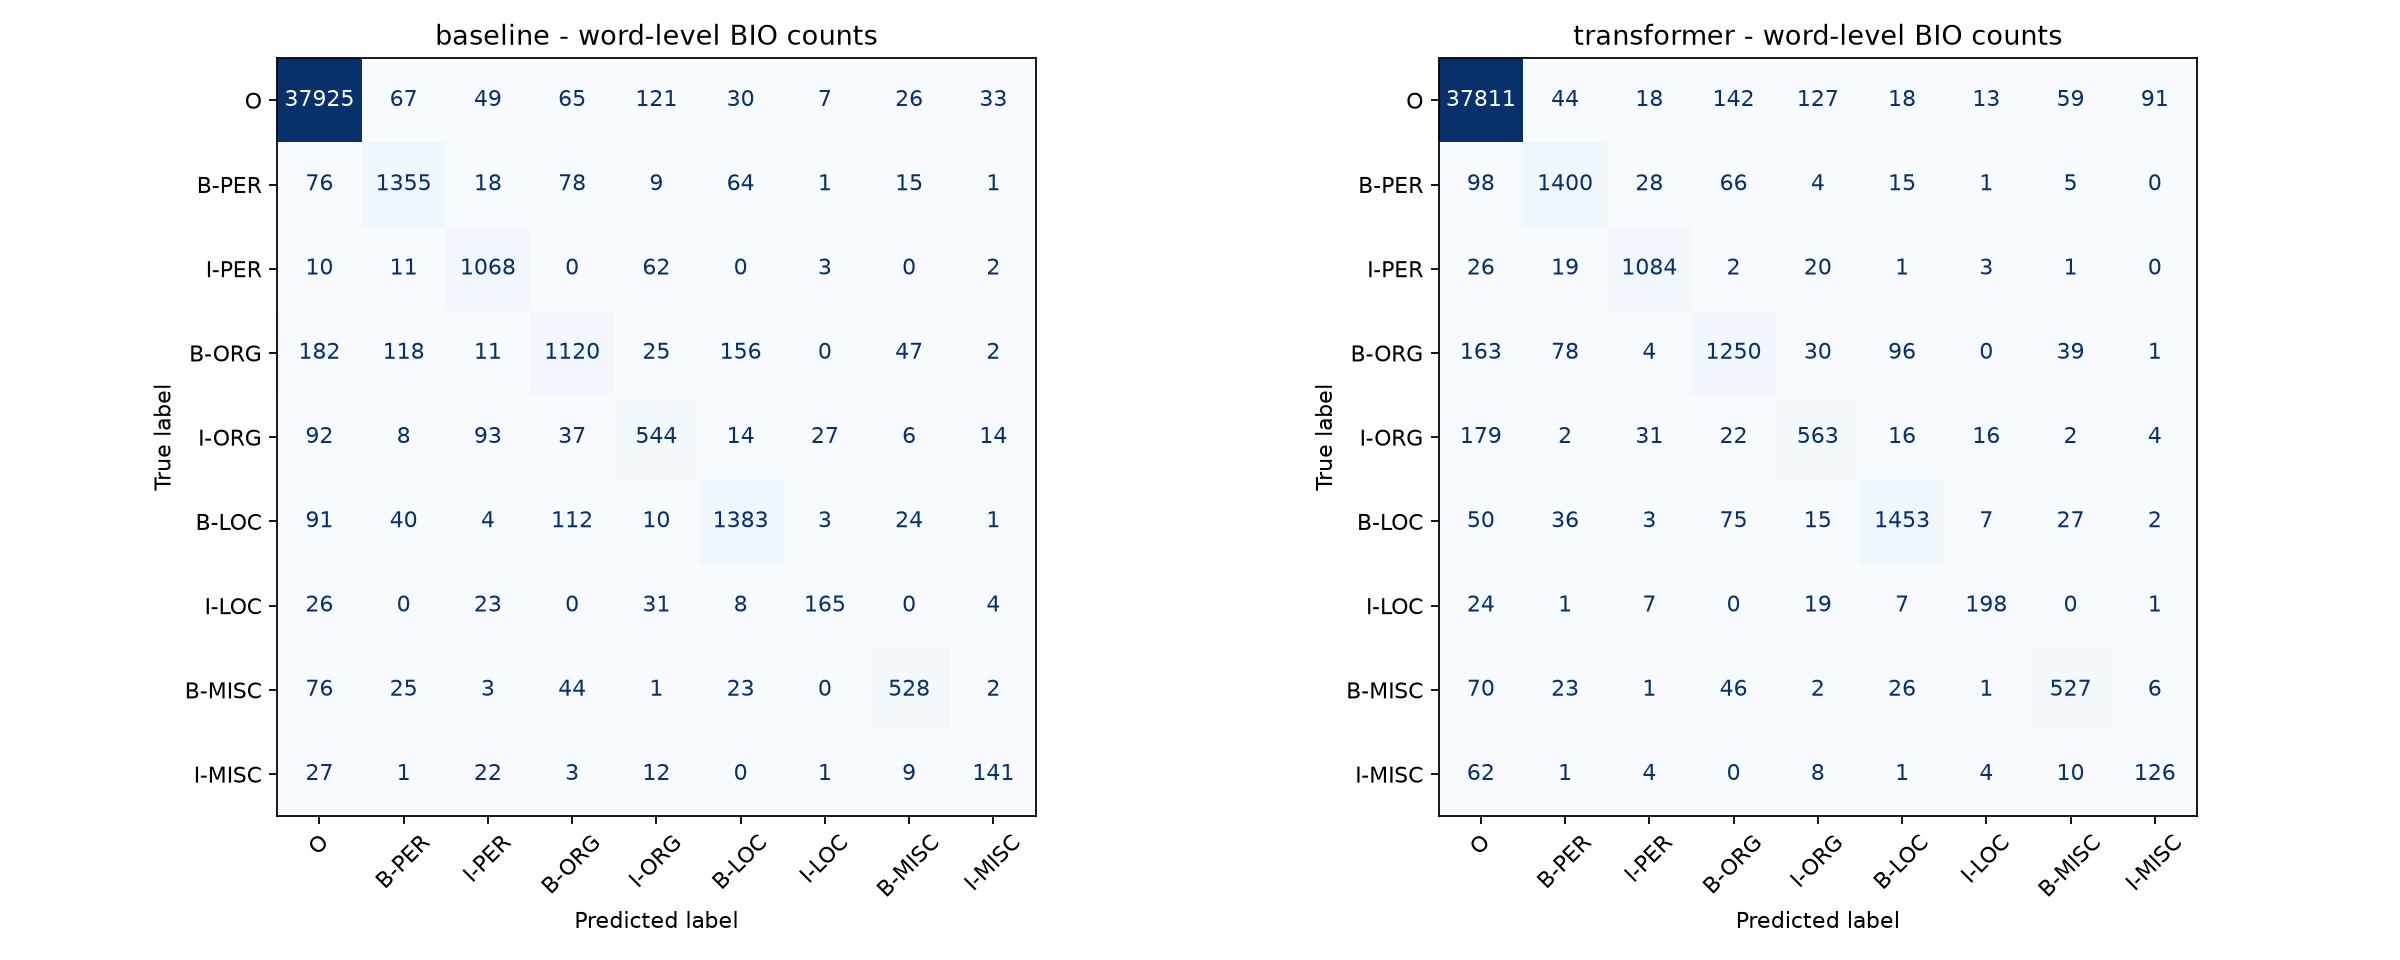

In [3]:
display(pd.read_csv('entity_metrics.csv'))
display(Image(filename='confusion_matrix.png'))

## Độ dài entity

,model,length,precision,recall,f1,tp,fp,fn,support
0,baseline,1,0.720565,0.756855,0.738264,2705,1049,869,3574
1,baseline,2,0.875163,0.753941,0.810042,1339,191,437,1776
2,baseline,3,0.815126,0.411017,0.546479,97,22,139,236
3,baseline,4+,0.785714,0.177419,0.289474,11,3,51,62
4,transformer,1,0.775477,0.806939,0.790895,2884,835,690,3574
5,transformer,2,0.881378,0.778153,0.826555,1382,186,394,1776
6,transformer,3,0.715847,0.555085,0.625298,131,52,105,236
7,transformer,4+,0.450000,0.290323,0.352941,18,22,44,62


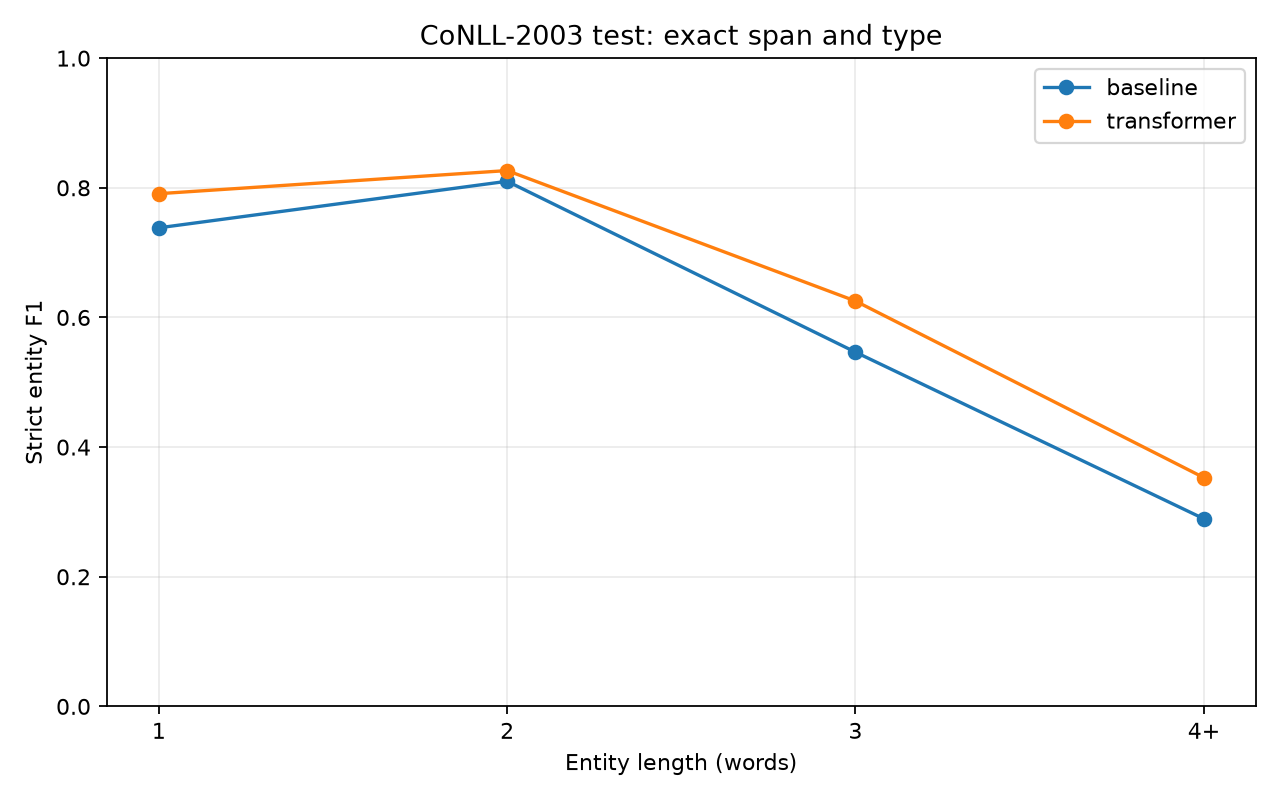

In [4]:
display(pd.read_csv('training_output/entity_length_metrics.csv'))
display(Image(filename='entity_length_analysis.png'))

## Ứng dụng IE: tin tức tiếng Anh

In [6]:
from information_extraction import InformationExtractor
extractor = InformationExtractor()
display(extractor.extract('Barack Obama visited Paris.'))
display(pd.Series(json.loads(Path('training_output/ie_metrics.json').read_text())))

{'PERSON': ['Barack Obama'],
 'ORGANIZATION': [],
 'LOCATION': ['Paris'],
 'MISC': [],
 'entities': [{'text': 'Barack Obama',
   'label': 'PERSON',
   'start': 0,
   'end': 12},
  {'text': 'Paris', 'label': 'LOCATION', 'start': 21, 'end': 26}]}

sentences    30.000000
precision     0.942857
recall        0.942857
f1            0.942857
tp           66.000000
fp            4.000000
fn            4.000000
support      70.000000
dtype: float64